# create project

## problem statment 
    predicat the price of hosue based on feature and train the model on past data 

In [1]:
# import librariy

import pandas as pd
import numpy as np

In [2]:
# read csv file

df = pd.read_csv(r"D:\SevenMentor\ML\workspace\Dhanaji_ml\dataset\House Price Prediction Dataset.csv")

In [3]:
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [4]:
df.tail()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


# perform EDA


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB


In [6]:
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [7]:
df.shape

(2000, 10)

In [47]:
# remove unwanted columns

df = df.drop("Id", axis = 1)
df = df.drop("Bathrooms", axis = 1)

In [9]:
df

,Area,Bedrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1360,5,3,1970,Downtown,Excellent,No,149919
1,4272,5,3,1958,Downtown,Excellent,No,424998
2,3592,2,3,1938,Downtown,Good,No,266746
3,966,4,2,1902,Suburban,Fair,Yes,244020
4,4926,1,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...
1995,4994,5,3,1923,Suburban,Poor,No,295620
1996,3046,5,1,2019,Suburban,Poor,Yes,580929
1997,1062,5,2,1903,Rural,Poor,No,476925
1998,4062,3,2,1936,Urban,Excellent,Yes,161119


In [10]:
# find the unique value of each columns

for i in df.columns:
    print(f"{i}:", df[i].unique(), "\n")

Area: [1360 4272 3592 ...  865 2174 4062] 

Bedrooms: [5 2 4 1 3] 

Floors: [3 2 1] 

YearBuilt: [1970 1958 1938 1902 1975 1906 1948 1925 1932 2000 1947 1978 1901 2004
 1931 1903 1919 2013 2016 1935 1927 1976 1900 1959 1955 1934 2011 1929
 1953 2020 1954 1988 1979 1957 1982 1964 1968 1950 1921 1987 2006 2008
 2015 1952 1999 1967 1951 1981 1949 1940 1917 1965 1920 1943 2002 1946
 1928 1989 1984 1916 1930 2014 1972 1994 1977 2009 1913 1996 1998 2010
 1983 2022 1915 1911 2018 1904 1980 2021 2005 1973 1942 1944 1908 1961
 1956 1924 1914 1905 2019 1941 1992 1974 1963 2001 1991 1936 1907 1997
 2007 2017 1966 1945 1912 1986 1960 1995 1933 1969 1923 2012 1910 2003
 1993 2023 1918 1971 1926 1939 1922 1937 1909 1990 1962 1985] 

Location: <StringArray>
['Downtown', 'Suburban', 'Urban', 'Rural']
Length: 4, dtype: str 

Condition: <StringArray>
['Excellent', 'Good', 'Fair', 'Poor']
Length: 4, dtype: str 

Garage: <StringArray>
['No', 'Yes']
Length: 2, dtype: str 

Price: [149919 424998 266746 ... 

In [11]:
# chack missing value

df.isna().sum()

Area         0
Bedrooms     0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

In [12]:
# chack dublicate value

df.duplicated().sum()

np.int64(0)

In [13]:
# chack for outlier
import matplotlib.pyplot as plt

Area


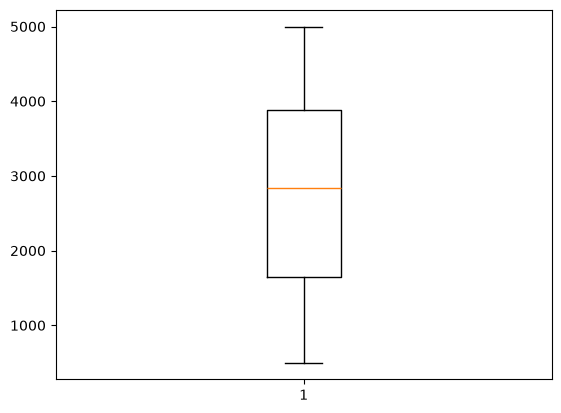

Bedrooms


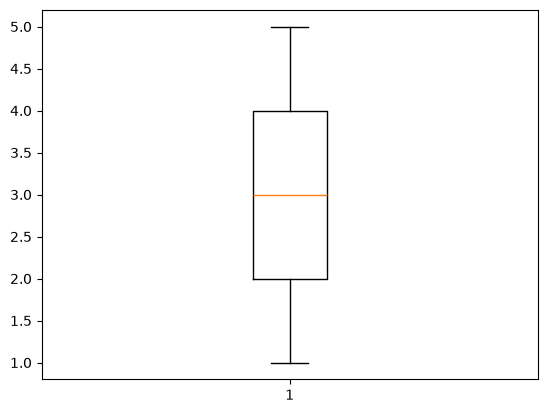

Floors


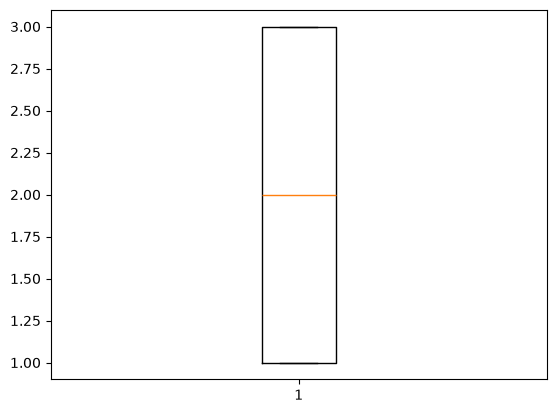

YearBuilt


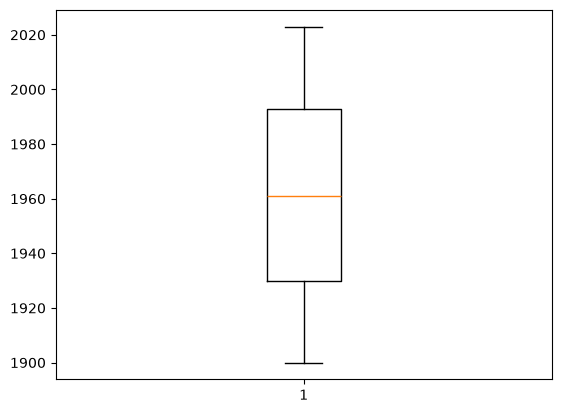

In [14]:
# plt.figure(figsize=(10,5))

def plots(df, x, y ="Price"):

    plt.boxplot(df[x])
    # plt.xlabel(x)
    # plt.ylabel(y)
    # plt.title(f"{x} vs {y}")
    plt.show()


for i in ['Area','Bedrooms', 'Floors', 'YearBuilt']:
    print(i)
    plots(df, i)

In [15]:
df.columns

Index(['Area', 'Bedrooms', 'Floors', 'YearBuilt', 'Location', 'Condition',
       'Garage', 'Price'],
      dtype='str')

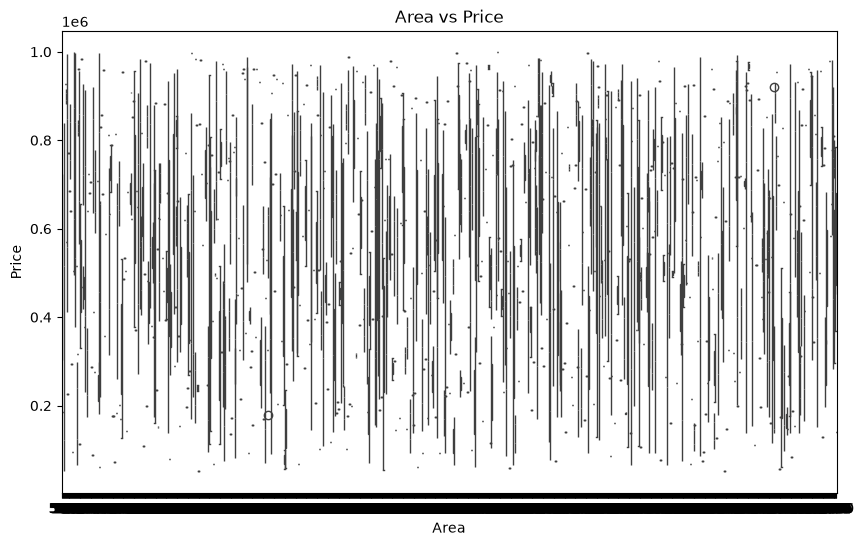

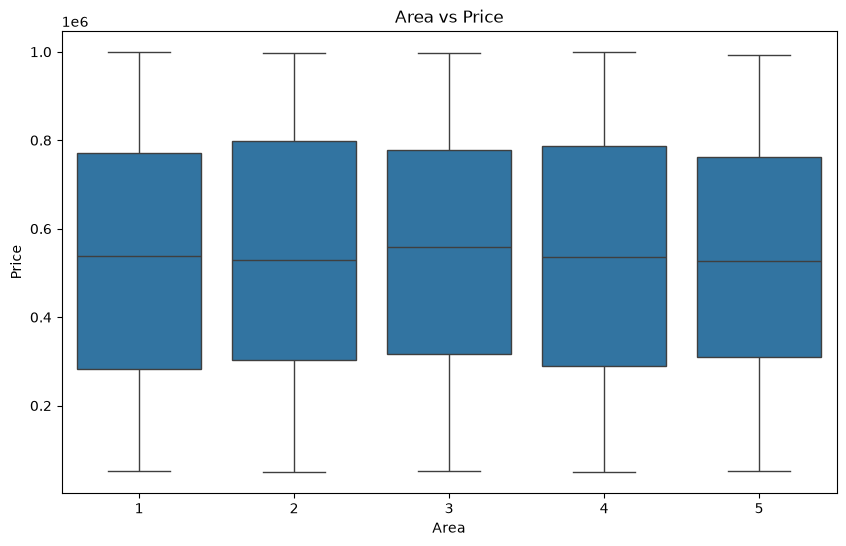

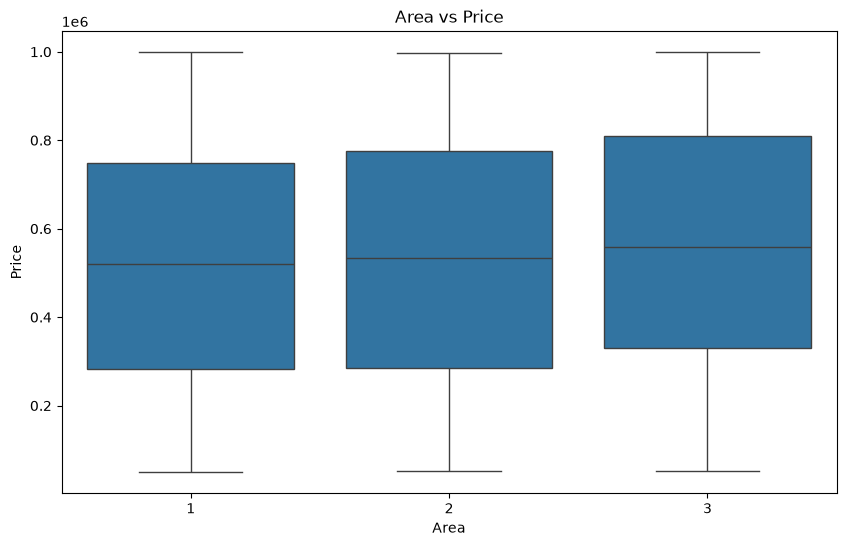

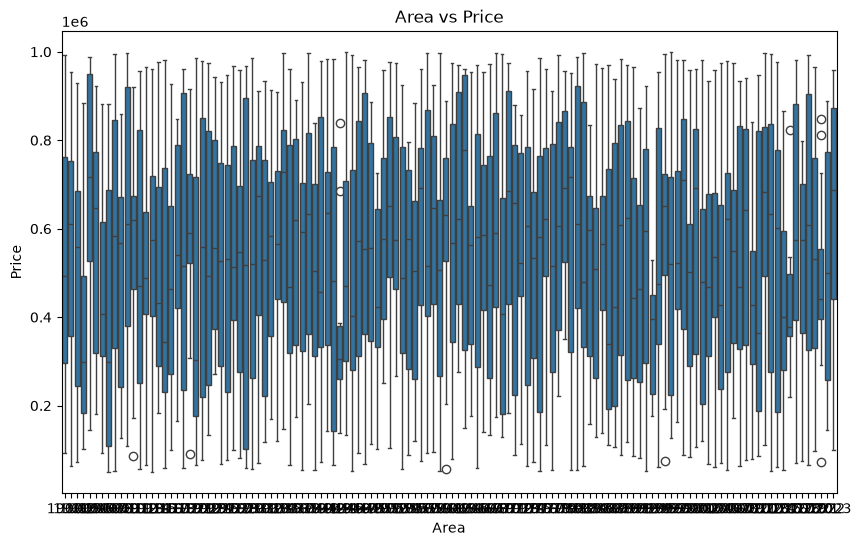

In [16]:
import seaborn as sb
import matplotlib.pyplot as plt

def plot(df, x, y="Price"):
    plt.figure(figsize=(10, 6))
    sb.boxplot(x=x, y='Price', data=df)
    plt.title('Area vs Price')
    plt.xlabel('Area')  
    plt.ylabel('Price')
    plt.show()

for i in ['Area', 'Bedrooms', 'Floors', 'YearBuilt']:
    plot(df, i)

# apply featuer engenering

In [17]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
st_en = StandardScaler()
or_en = OrdinalEncoder()

In [18]:
y = df["Price"]
X = df.drop("Price", axis= 1)

In [19]:
cat = []
num = []

for i in X.columns:
    if df[i].dtype == "int":
        num.append(i)
    else:
        cat.append(i)

In [20]:
cat

['Location', 'Condition', 'Garage']

In [21]:
num

['Area', 'Bedrooms', 'Floors', 'YearBuilt']

# split data 

In [22]:
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1600, 7)
(400, 7)
(1600,)
(400,)


In [24]:
# peform encoding

# x_train_num = st_en.fit_transform(x_train[num])
x_train_cat = or_en.fit_transform(x_train[cat])
# x_train_en = pd.concat([pd.DataFrame(x_train_num, columns= st_en.get_feature_names_out()), pd.DataFrame(x_train_cat, columns=or_en.get_feature_names_out())], axis=1)
x_train[] = 

x_test_num = st_en.transform(x_test[num])
x_test_cat = or_en.transform(x_test[cat])
x_test_en = pd.concat([pd.DataFrame(x_test_num, columns= st_en.get_feature_names_out()), pd.DataFrame(x_test_cat, columns=or_en.get_feature_names_out())], axis=1)
# x_test_en = pd.concat([st_en.transform(x_test[num]), or_en.transform(x_test[cat])])


In [25]:
x_train_en.isnull().sum()

Area         0
Bedrooms     0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
dtype: int64

In [26]:
x_train.shape

(1600, 7)

# proform model

In [27]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(x_train_en, y_train)

y_pred = model.predict(x_test_en)

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mean_absolute_error(y_pred, y_test)


243042.66942033026

In [37]:
test = pd.DataFrame(y_test)

In [39]:
test["pred"] = y_pred

In [40]:
test

,Price,pred
1860,514764,525956.289194
353,694256,524426.703910
1333,66375,518545.042822
905,650243,544477.986161
1289,223285,567642.419254
...,...,...
965,386940,555743.132588
1284,632570,543943.758670
1739,494049,534227.362233
261,562193,533899.692631


In [32]:
y_test

1860    514764
353     694256
1333     66375
905     650243
1289    223285
         ...  
965     386940
1284    632570
1739    494049
261     562193
535     447530
Name: Price, Length: 400, dtype: int64

# re chack of dataset

# How to Vet a Dataset Before Modeling — A Practical EDA Checklist

You learned an expensive lesson yesterday. Let's turn it into a permanent skill. The rule is:

> **Never train a model until EDA has proven that signal exists.**

Here's a systematic workflow to catch "garbage datasets" *before* wasting hours.

---

## Part 1 — The 15-Minute Dataset Triage

Run this **first**, every single time, before touching a model.

### Step 1: Structural Sanity

```python
df.shape                 # rows, cols
df.info()                # dtypes, non-null counts
df.head(10)
df.tail(10)
df.describe().T          # stats for numeric cols
df.nunique()             # cardinality — catch constant/ID columns
```

**Red flags:**
- A column with `nunique == 1` (constant) → drop it
- A column with `nunique == len(df)` → probably an ID → drop it
- Numeric columns stored as `object` dtype → encoding issue upstream
- `describe()` showing min/max that violate reality (negative prices, age > 200)

### Step 2: The Correlation Reality Check (most important)

```python
corr = df.corr(numeric_only=True)['Price'].sort_values()
print(corr)
```

**Interpretation for your house dataset:**

| Max abs correlation | Verdict |
|---|---|
| > 0.5 | Strong signal — great |
| 0.2 – 0.5 | Weak but usable |
| 0.05 – 0.2 | Very weak — needs feature engineering |
| **< 0.05** | **🚨 No signal — STOP, don't model** |

Your dataset hit the last row. That alone would have saved you the whole day.

### Step 3: Visual Signal Check

Numbers lie; plots don't. For **regression** targets:

```python
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter every feature vs target
num_cols = df.select_dtypes('number').columns.drop('Price')
fig, axes = plt.subplots(1, len(num_cols), figsize=(4*len(num_cols), 4))
for ax, col in zip(axes, num_cols):
    ax.scatter(df[col], df['Price'], s=5, alpha=0.4)
    ax.set_xlabel(col); ax.set_ylabel('Price')
plt.tight_layout(); plt.show()
```

**If every scatter looks like a shapeless cloud → no linear signal.** For your data, that's exactly what you'd see.

For **categorical** features vs target:

```python
for col in ['Location', 'Condition', 'Garage']:
    sns.boxplot(data=df, x=col, y='Price')
    plt.title(f'Price by {col}')
    plt.show()
```

If the boxes all sit at the same height → the category doesn't matter.

### Step 4: The "Target Mean Baseline" Test

This is the **single fastest kill-switch** for a bad dataset:

```python
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

# Baseline: always predict the mean
baseline = cross_val_score(
    DummyRegressor(strategy='mean'),
    X, y, cv=5, scoring='r2'
).mean()
print("Baseline R² (predict mean):", baseline)   # always ≈ 0

# Your model
model_r2 = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2').mean()
print("Model R²:", model_r2)
```

**Decision rule:**
- If `model_r2` is not **meaningfully higher** than baseline (e.g., +0.10 or more) → **the features carry no information.** Stop.

For your dataset, model R² ≈ 0.00 = baseline. Immediate red flag.

### Step 5: Shuffle Test (Detects "Leakage" and "Fake" Signals)

Scramble the target and retrain. If your model still scores well, something is wrong (e.g., an ID column leaking).

```python
from sklearn.utils import shuffle

y_shuffled = shuffle(y, random_state=0)
r2_shuffled = cross_val_score(
    LinearRegression(), X, y_shuffled, cv=5, scoring='r2'
).mean()
print("R² with shuffled target:", r2_shuffled)  # should be ≈ 0 or negative
```

If real R² ≈ shuffled R² ≈ 0 → **the dataset is noise.**

---

## Part 2 — Feature Engineering That Reveals Signal

Sometimes raw features are weak but combinations are strong. Try these before giving up:

### 1. Domain-driven ratios

```python
df['Age']          = 2024 - df['YearBuilt']
df['AreaPerRoom']  = df['Area'] / (df['Bedrooms'] + df['Bathrooms'] + 1)
df['TotalRooms']   = df['Bedrooms'] + df['Bathrooms']
df['IsNew']        = (df['YearBuilt'] > 2010).astype(int)
```

Then recheck correlation:

```python
df.corr(numeric_only=True)['Price'].sort_values()
```

If even engineered features stay at |r| < 0.05 → give up on linear models with this data.

### 2. Non-linear relationship check

A feature can correlate ~0 with the target but still be useful non-linearly. Test with a tree model:

```python
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

rf_r2 = cross_val_score(
    RandomForestRegressor(n_estimators=200, random_state=0),
    X, y, cv=5, scoring='r2'
).mean()
print("Random Forest R²:", rf_r2)
```

**Key insight:** If linear R² ≈ 0 but RF R² is high → non-linear signal exists.
If **both** ≈ 0 → the data is truly random. You now *know* it, no guessing.

### 3. Feature importance check

```python
rf = RandomForestRegressor(n_estimators=300, random_state=0).fit(X, y)
import pandas as pd
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
print(imp)
```

If all importances are ≈ 1/n_features → random data confirmed.

---

## Part 3 — Choosing the Right Model for the Right Data

Once you've confirmed signal exists, pick the model based on **data characteristics**, not preference.

| Situation | Best first model | Why |
|---|---|---|
| Linear relationships, few features | **Linear / Ridge / Lasso** | Interpretable, fast |
| Linear + many correlated features | **Ridge / ElasticNet** | Handles multicollinearity |
| Non-linear, tabular, < 100k rows | **Random Forest / Gradient Boosting** | Captures interactions |
| Tabular, need max accuracy | **XGBoost / LightGBM / CatBoost** | Usually SOTA on tabular |
| Small n (< 500) | **Linear + CV, then RF** | Avoid overfitting |
| High-dimensional (p > n) | **Lasso / ElasticNet** | Built-in feature selection |
| Time-series prices | **ARIMA / Prophet / LSTM** | Respect temporal order |
| Text/categorical-heavy | **Target encoding + GBM** | Handles categories well |

### Decision flowchart

```
1. Is there signal? (correlation / RF test)
   NO  → Stop. Fix data.
   YES → continue

2. Is the relationship roughly linear?
   YES → Linear / Ridge / Lasso
   NO  → Tree-based (RF → GBM)

3. Do you need interpretability?
   YES → Linear or SHAP on GBM
   NO  → GBM / XGBoost

4. Is n small (< 1000)?
   YES → Use cross-validation everywhere, prefer simpler models
   NO  → Try boosting, tune hyperparams

5. Is it temporal?
   YES → TimeSeriesSplit, not random split
```

---

## Part 4 — The Pre-Modeling Checklist (Print This)

Before fitting anything, confirm **all** of these:

- [ ] `df.info()` — dtypes correct, no surprise nulls
- [ ] Dropped ID / constant columns
- [ ] `df.describe()` — no impossible values
- [ ] Target distribution plotted — no crazy skew without reason
- [ ] **Correlation of each feature with target computed** ← the money step
- [ ] At least one feature has |corr| > 0.1, OR RF test shows R² > 0.1
- [ ] Scatter plots of top-correlated features look non-random
- [ ] Baseline (predict mean) R² computed
- [ ] Shuffle test passes (shuffled R² ≈ 0)

**If any check fails → do not proceed to hyperparameter tuning.** You'd be polishing a rock.

---

## Part 5 — Applied to Your House Dataset

Here's exactly what *should have happened* yesterday:

```python
# 1. Correlations
corr = df.corr(numeric_only=True)['Price'].drop('Price')
print(corr.abs().max())        # → ~0.02  🚨

# 2. RF test
rf_r2 = cross_val_score(RandomForestRegressor(n_estimators=200),
                        X, y, cv=5, scoring='r2').mean()
print(rf_r2)                   # → ~0.00  🚨

# 3. Shuffle test
print(cross_val_score(LinearRegression(), X,
      shuffle(y, random_state=0), cv=5, scoring='r2').mean())  # → ~0.00
```

Three independent tests all say the same thing in **under 60 seconds**: *no signal*. That's your early-exit trigger.

---

## The One-Sentence Rule to Remember

> **"Before I tune a model, I must have already seen — with a number or a plot — that at least one feature moves with the target."**

Everything you suffered yesterday collapses into that single habit.

---

Want me to:
1. Build you a **reusable `audit_dataset()` function** that runs all these checks and prints a verdict?
2. Show the same workflow on a **known-good dataset** (e.g., California Housing) so you can compare what "signal" looks like?
3. Go deeper into **non-linear signal detection** (mutual information, partial dependence)?

In [74]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"D:\SevenMentor\ML\workspace\Dhanaji_ml\dataset\House Price Prediction Dataset.csv").drop("Id", axis = 1)

In [75]:
df.shape

(2000, 9)

In [76]:
 df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,2000.0,2786.2095,1295.146799,501.0,1653.0,2833.0,3887.5,4999.0
Bedrooms,2000.0,3.0035,1.424606,1.0,2.0,3.0,4.0,5.0
Bathrooms,2000.0,2.5525,1.108990,1.0,2.0,3.0,4.0,4.0
Floors,2000.0,1.9935,0.809188,1.0,1.0,2.0,3.0,3.0
YearBuilt,2000.0,1961.4460,35.926695,1900.0,1930.0,1961.0,1993.0,2023.0
Price,2000.0,537676.8550,276428.845719,50005.0,300098.0,539254.0,780086.0,999656.0


In [77]:
df.nunique()

Area         1622
Bedrooms        5
Bathrooms       4
Floors          3
YearBuilt     124
Location        4
Condition       4
Garage          2
Price        1999
dtype: int64

In [78]:
df["Price"]

0       149919
1       424998
2       266746
3       244020
4       636056
         ...  
1995    295620
1996    580929
1997    476925
1998    161119
1999    482525
Name: Price, Length: 2000, dtype: int64

In [79]:
# the correleation
corr = df.corr(numeric_only=True)["Price"].sort_values()

In [80]:
corr

Bathrooms   -0.015737
Bedrooms    -0.003471
Area         0.001542
YearBuilt    0.004845
Floors       0.055890
Price        1.000000
Name: Price, dtype: float64

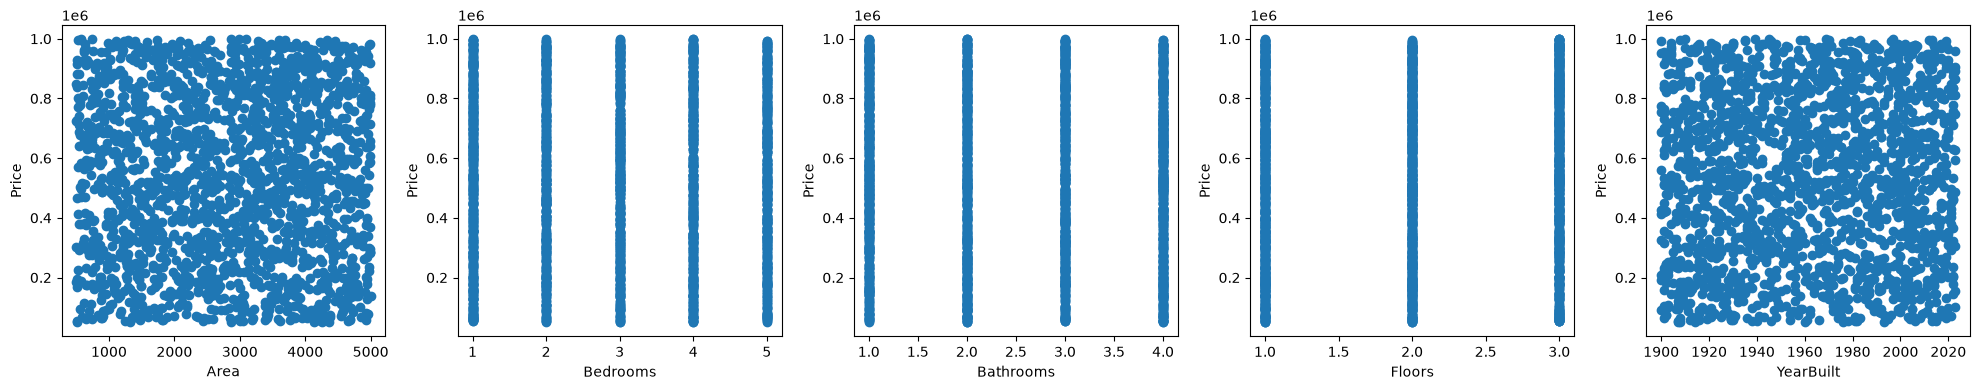

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter every feature vs target
num_cols = df.select_dtypes("number").columns.drop("Price")
fig, axes = plt.subplots(1, len(num_cols), figsize = (4*len(num_cols), 4))

for ax, col in zip(axes, num_cols):
    ax.scatter(df[col], df["Price"])
    ax.set_xlabel(col),
    ax.set_ylabel("Price")

plt.tight_layout()
plt.show()


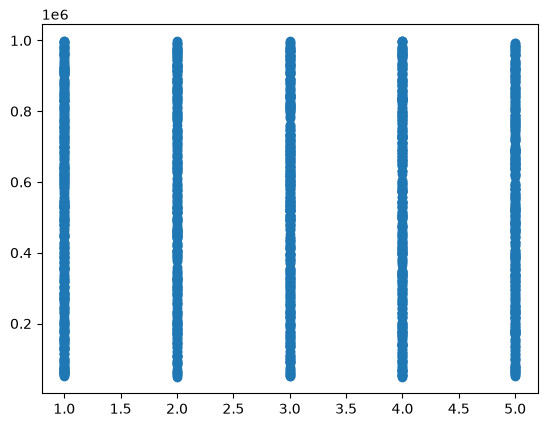

In [82]:
plt.scatter(df["Bedrooms"], df["Price"])

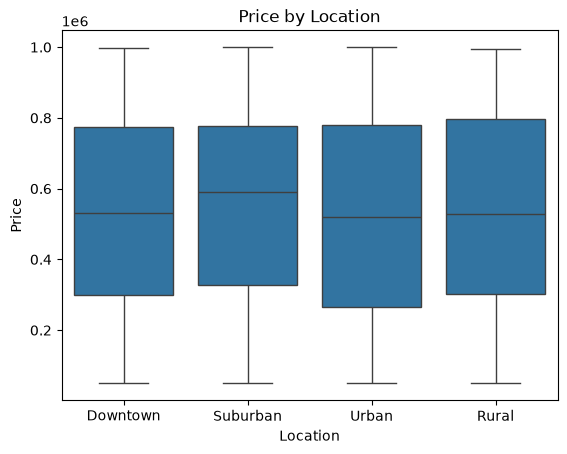

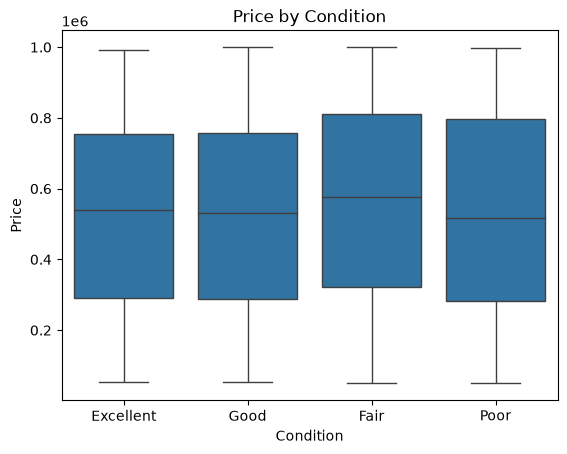

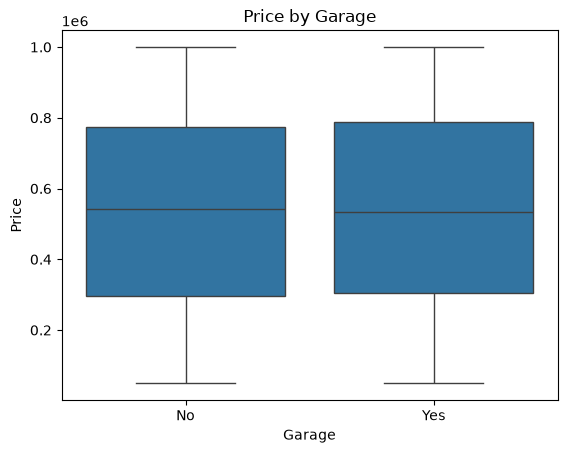

In [83]:
for col in ['Location', 'Condition', 'Garage']:
    sns.boxplot(data=df, x=col, y='Price')
    plt.title(f'Price by {col}')
    plt.show()


In [84]:
X = df.drop("Price", axis = 1)
y = df["Price"]

In [85]:
cot = [x for x in X.columns if X[x].dtype != "int"]



In [86]:
from sklearn.preprocessing import OrdinalEncoder

X[cot] = OrdinalEncoder().fit_transform(X[cot])

In [87]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

# Baseline: always predict the mean
baseline = cross_val_score(
    DummyRegressor(strategy='mean'),
    X, y, cv=5, scoring='r2'
).mean()
print("Baseline R² (predict mean):", baseline)   # always ≈ 0

# Your model
model_r2 = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2').mean()
print("Model R²:", model_r2)

Baseline R² (predict mean): -0.003948893793392827
Model R²: -0.007117266840980951


In [88]:
from sklearn.utils import shuffle

y_shuffled = shuffle(y, random_state=0)
r2_shuffled = cross_val_score(
    LinearRegression(), X, y_shuffled, cv=5, scoring='r2'
).mean()
print("R² with shuffled target:", r2_shuffled)  # should be ≈ 0 or negative

R² with shuffled target: -0.01013134910901865


In [89]:
df['Age']          = 2024 - df['YearBuilt']
df['AreaPerRoom']  = df['Area'] / (df['Bedrooms'] + df['Bathrooms'] + 1)
df['TotalRooms']   = df['Bedrooms'] + df['Bathrooms']
df['IsNew']        = (df['YearBuilt'] > 2010).astype(int)


In [90]:
df.corr(numeric_only=True)['Price'].sort_values()


Bathrooms     -0.015737
TotalRooms    -0.012478
AreaPerRoom   -0.007145
Age           -0.004845
Bedrooms      -0.003471
Area           0.001542
IsNew          0.002883
YearBuilt      0.004845
Floors         0.055890
Price          1.000000
Name: Price, dtype: float64

In [92]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

rf_r2 = cross_val_score(
    RandomForestRegressor(n_estimators=200, random_state=0),
    X, y, cv=10, scoring='r2'
).mean()
print("Random Forest R²:", rf_r2)


Random Forest R²: -0.07810330637241514


# conclusion: Dataset is purelly noise, model can not predict 